[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_RQI_Mosaic_SpatialBias_DualPol/blob/main/notebooks/04_hybrid_scan_rqi_mosaic.ipynb)

# 04 · Hybrid scan และการโมเสคเรดาร์หลายสถานีด้วย RQI
*Hybrid scans and RQI-weighted multi-radar mosaics*

| | |
|---|---|
| **ระดับ** | 🟢 ป.ตรี ปี 3–4 และ 🔵 ป.โท |
| **เวลาโดยประมาณ** | 120 นาที |
| **ควรผ่านมาก่อน** | 02, 03 |
| **ข้อมูลเข้า** | UF 5 เรดาร์ × 5 สแกน (00:00–01:00 UTC), DEM, ค่าปรับเทียบ |
| **ผลลัพธ์** | โมเสคฝน 15 นาทีและรายชั่วโมง 4 ผลิตภัณฑ์, แผนที่ RQI, ตารางฝนรายลุ่มน้ำ, GeoTIFF |

> 📌 **วิธีใช้:** กด *Runtime ▸ Run all* ได้ทันที หรือรันทีละเซลล์ (Shift+Enter) พร้อมอ่านคำอธิบาย
> เซลล์ที่มีหัวข้อ 🔑 เป็นเฉลยที่ซ่อนไว้ ลองทำแบบฝึกหัดก่อนแล้วค่อยเปิดดู

## 🎯 วัตถุประสงค์การเรียนรู้
1. **อธิบาย** หลักการ hybrid scan ของ NEXRAD และแนวคิด polarimetric hybrid scan
2. **รวม (โมเสค)** ฝนจากเรดาร์ 5 สถานีด้วยการถ่วงน้ำหนัก RQI และเปรียบเทียบกับการเลือกเรดาร์ที่ดีที่สุด
3. **สะสม** ฝนจากสแกน 15 นาทีเป็นรายชั่วโมง พร้อมเกณฑ์ความครบของข้อมูล
4. **เปรียบเทียบ** ผลิตภัณฑ์ 4 แบบ (LS_MP, LS_DP, HYZ_MP, PHY_DP) ทั้งด้านพื้นที่ครอบคลุมและปริมาณฝน
5. **ส่งออก** ผลเป็น GeoTIFF เพื่อใช้ใน GIS

## 1. หลักการ
### 1.1 Hybrid scan (Fulton et al. 1998, NEXRAD)
แทนที่จะใช้มุมต่ำสุดอย่างเดียว ให้เลือก **มุมยกที่ต่ำที่สุดที่ "ใช้ได้"** ในแต่ละ bin:
- ลำคลื่นถูกบัง CBB < 0.5
- ฐานลำคลื่นสูงจากพื้นอย่างน้อย 150 ม. (กันสัญญาณสะท้อนจากพื้น)
- (ถ้าเป็นไปได้) อยู่ใต้ชั้นหลอมเหลว
ถ้าบังมาก จึงขยับไปมุมถัดไป → แลกระหว่าง "ไม่ถูกบัง" กับ "ลำคลื่นสูงขึ้น"

### 1.2 Polarimetric hybrid scan (แนวคิดของรายวิชานี้)
ตัวประมาณที่ใช้เฟส (R(KDP), R(A)) ไม่ได้รับผลจากการบังบางส่วน (Germann et al. 2022) จึงยอมให้ใช้มุมที่ต่ำกว่าได้ถึง CBB < 0.7
ส่วนตัวประมาณที่ใช้ Z ต้องแก้ค่าการบัง $\Delta Z = -10\log_{10}(1-\text{CBB})$ และใช้ได้ถึง CBB < 0.5

### 1.3 การโมเสค
$$R_{\text{mosaic}}(x) = \frac{\sum_i \text{RQI}_i(x)\,R_i(x)}{\sum_i \text{RQI}_i(x)} \quad\text{(ถ่วงน้ำหนัก, MRMS)} \qquad\text{หรือ}\qquad R_{\text{mosaic}}(x) = R_{i^*}(x),\ i^* = \arg\max_i \text{RQI}_i(x)$$

### 1.4 จาก 15 นาทีเป็นรายชั่วโมง
กรมอุตุฯ สแกนทุก 15 นาที ถือว่าความเข้มฝนคงที่ระหว่างสแกน: $D_{1h} = \sum_{k=1}^{4} R_k\,\Delta t$, $\Delta t = 0.25$ ชม.
ถ้าขาดสแกน 1 ใน 4 ให้แทนด้วยค่าเฉลี่ยของที่เหลือ (ต้องมีอย่างน้อย 3 สแกน) — ผลของสมมติฐาน "คงที่" ศึกษาใน notebook 05

### 1.5 ผลิตภัณฑ์ในรายวิชา
| ชื่อ | มุมยก | ตัวประมาณ | แก้การบัง | VPR |
|---|---|---|---|---|
| **LS_MP** | ต่ำสุด | Z–R MP | – | ตัดทิ้งเหนือชั้นหลอมเหลว |
| **LS_DP** | ต่ำสุด | blended | – | ตัดทิ้ง |
| **HYZ_MP** | hybrid (Z) | Z–R MP | ✔ | ✔ (notebook 05) |
| **PHY_DP** | polarimetric hybrid | KDP/A ถ้ามี, ไม่งั้น HYZ | ✔ | ✔ |

In [1]:
PACKAGES = ('teaching_data', 'products')
#@title ⚙️ เตรียมสภาพแวดล้อม (รันเซลล์นี้ก่อนทุกครั้ง) { display-mode: "form" }
import os, sys, subprocess
REPO, OWNER = "Teach_RQI_Mosaic_SpatialBias_DualPol", "nattaponm"
if "google.colab" in sys.modules:
    if not os.path.exists(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        f"https://github.com/{OWNER}/{REPO}.git", f"/content/{REPO}"], check=True)
    os.chdir(f"/content/{REPO}")
else:  # running on your own computer: move to the repository root
    while not os.path.exists("config/study_area.yaml") and os.getcwd() != os.path.dirname(os.getcwd()):
        os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
from radteach import colab
P = colab.setup(packages=PACKAGES)

installing: arm_pyart (about 1–2 minutes the first time) …
downloading teaching_data_v1.zip …
teaching_data_v1.zip ready in /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw
downloading teaching_products_v1.zip …
teaching_products_v1.zip ready in /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw
repository : /content/Teach_RQI_Mosaic_SpatialBias_DualPol
Colab      : True
Thai font  : Sarabun
data       : /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw


## 2. มุมยกที่ hybrid scan เลือก
คำนวณจากเรขาคณิตอย่างเดียว (ไม่ต้องใช้ข้อมูลฝน) สำหรับ LMP และ TAK ซึ่งอยู่ในพื้นที่ภูเขา

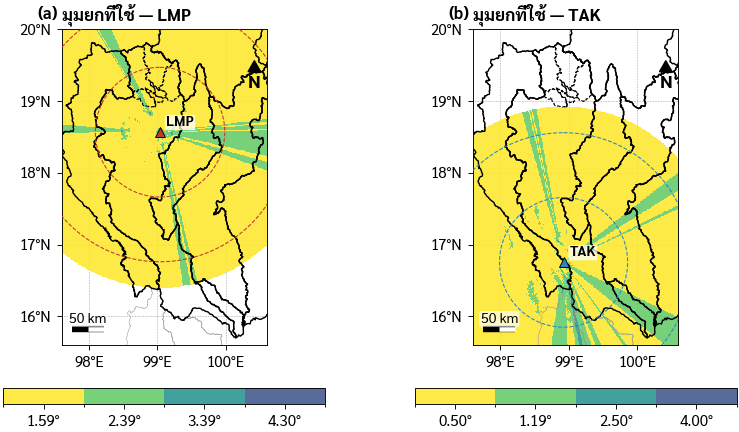

สีแดง = ไม่มีมุมยกใดผ่านเกณฑ์ (บังทุกมุมหรือชิดพื้นเกินไป)


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from radteach import dem, io, qc, mosaic, rqi as RQ, config, plotting as pl, mapping as mp
cfg = config.load_all(); g = cfg["study_area"]["grid"]
glon, glat = mosaic.make_grid(g["lon_min"], g["lon_max"], g["lat_min"], g["lat_max"], g["res_deg"])
z, tr, _ = dem.read(P.products / "dem_study_area.tif"); terrain = dem.interpolator(z, tr)
scans = io.list_scans(P.radar / "20241003_00UTC")
geoms = {}
for rad in ["LMP", "TAK"]:
    rd = io.read_radar(scans[scans.radar == rad].path.iloc[0])
    geoms[rad] = mosaic.radar_geometry(rd, terrain)
from matplotlib.colors import ListedColormap, BoundaryNorm
fig, axs = pl.subplots(1, 2, width="double", height_mm=100)
for ax, rad in zip(axs, geoms):
    G = geoms[rad]; C = np.array([x["cbb"] for x in G]); CL = np.array([x["clearance"] for x in G])
    ok = (C < 0.5) & (CL >= 150)
    k = np.where(ok.any(0), ok.argmax(0), -1)
    els = [x["el"] for x in G]
    m = mosaic.PolarToGrid(G[0]["lon0"], G[0]["lat0"], mosaic.AZ_GRID, G[0]["r"], glon, glat)
    kk = m(k.astype(float))
    cmap = ListedColormap(["#fde725", "#5ec962", "#21918c", "#3b528b"][:len(els)]); cmap.set_bad((1, 1, 1, 0))
    im = mp.show_grid(ax, np.where(kk >= 0, kk, np.nan), glon, glat, cmap, BoundaryNorm(np.arange(-0.5, len(els)), len(els)), alpha=0.85)
    ax.imshow(np.where(kk < 0, 1, np.nan), extent=mp.grid_extent(glon, glat), cmap=ListedColormap(["#d62728"]), zorder=2.5)
    mp.basemap(ax, cfg["study_area"]["map_extent"]["ping_wang"], radars=[rad], rings_km=[100, 200],
               subbasins=cfg["study_area"]["ping_headwater_subbasins"], title=f"มุมยกที่ใช้ — {rad}")
    cb = fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.8, ticks=range(len(els)))
    cb.ax.set_xticklabels([f"{e:.2f}°" for e in els])
pl.panel_labels(axs); pl.save(fig, "04_hybrid_scan_elevation"); plt.show()
print("สีแดง = ไม่มีมุมยกใดผ่านเกณฑ์ (บังทุกมุมหรือชิดพื้นเกินไป)")

**สังเกต:** หลังภูเขาสูง (ดอยอินทนนท์ ทางตะวันตกของ LMP) hybrid scan ขยับไปใช้มุม 2.39° หรือ 3.39° ส่วน TAK ที่อยู่บนดอยสูง
ใช้มุม 0.5° ได้ในทิศที่ไม่มีภูเขาบัง แต่ในหลายทิศต้องขยับขึ้นไปเป็นมุมที่สูงกว่า

## 3. รันกระบวนการโมเสคเต็มรูปแบบ (1 ชั่วโมง, 5 เรดาร์ × 5 สแกน)
ขั้นตอนใน `mosaic.process_hour`:
1. **pass 1** — ทุกไฟล์: QC, KDP, ZPHI, R(Z), R(A), R(KDP) ทุกมุมยก (notebook 01, 03) + เก็บตัวอย่างสำหรับ VPR
2. หาชั้นหลอมเหลวและ VPR (notebook 05)
3. **pass 2** — ทุกสแกน: เลือกมุมยก (LS / HYZ / PHY), คำนวณ RQI, แปลงลงกริด, โมเสคถ่วงน้ำหนัก

ใช้เวลาประมาณ 1–3 นาทีใน Colab ถ้าไม่ต้องการรอ ตั้ง `RUN_FULL = False` เพื่อโหลดผลสำเร็จรูป

In [3]:
RUN_FULL = True    #@param {type:"boolean"}
cal = pd.read_csv(P.products / "calibration_20241003_00UTC.csv", index_col=0)
if RUN_FULL:
    res = mosaic.process_hour(scans, terrain, cal, glon, glat)
    mosaic.save_npz(P.processed / "mosaic_20241003_00UTC.npz", res)
else:
    res = dict(np.load(P.products / "mosaic_20241003_00UTC.npz", allow_pickle=True))
ref = np.load(P.products / "mosaic_20241003_00UTC.npz")
for p in mosaic.PRODUCTS:
    a, b = res[f"h_{p}"], ref[f"h_{p}"]; k = np.isfinite(a) & np.isfinite(b)
    print(f"{p:7s} ฝนเฉลี่ยทั้งโดเมน {np.nanmean(a):.3f} มม. | ตรงกับผลสำเร็จรูป r = {np.corrcoef(a[k], b[k])[0, 1]:.4f}")

  pass 1 00:00  (33 s)
  pass 1 00:15  (59 s)
  pass 1 00:30  (86 s)
  pass 1 00:45  (113 s)
  pass 1 01:00  (140 s)
  melting layer 4800–6600 m (ρhv dip (min 0.935 at 6500 m)); Z_ref 18.9 dBZ
  pass 2 00:00  (143 s)
  pass 2 00:15  (145 s)
  pass 2 00:30  (146 s)
  pass 2 00:45  (147 s)
  pass 2 01:00  (148 s)
  done in 149 s
LS_MP   ฝนเฉลี่ยทั้งโดเมน 0.113 มม. | ตรงกับผลสำเร็จรูป r = 1.0000
LS_DP   ฝนเฉลี่ยทั้งโดเมน 0.141 มม. | ตรงกับผลสำเร็จรูป r = 1.0000
HYZ_MP  ฝนเฉลี่ยทั้งโดเมน 0.092 มม. | ตรงกับผลสำเร็จรูป r = 1.0000
PHY_DP  ฝนเฉลี่ยทั้งโดเมน 0.129 มม. | ตรงกับผลสำเร็จรูป r = 1.0000


## 4. แผนที่ฝนรายชั่วโมง 4 ผลิตภัณฑ์

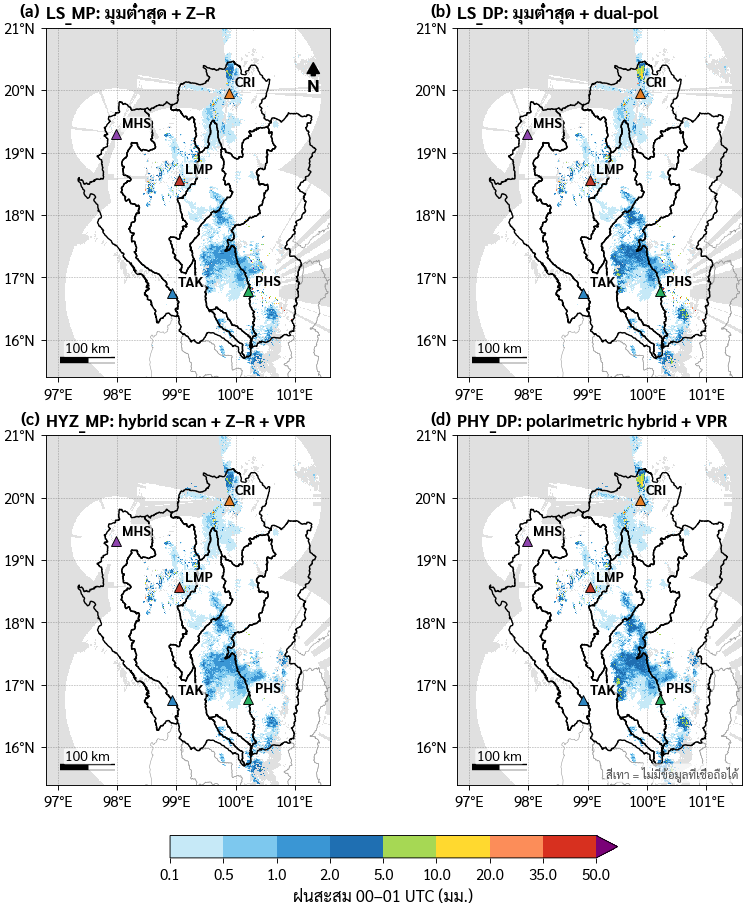

In [4]:
E = cfg["study_area"]["map_extent"]["north"]
cm, nm = pl.rain_cmap()
fig, axs = pl.subplots(2, 2, width="double", height_mm=210)
titles = {"LS_MP": "LS_MP: มุมต่ำสุด + Z–R", "LS_DP": "LS_DP: มุมต่ำสุด + dual-pol",
          "HYZ_MP": "HYZ_MP: hybrid scan + Z–R + VPR", "PHY_DP": "PHY_DP: polarimetric hybrid + VPR"}
for ax, p in zip(axs.ravel(), mosaic.PRODUCTS):
    im = mp.show_grid(ax, res[f"h_{p}"], glon, glat, cm, nm)
    nodata = np.where(np.isnan(res[f"h_{p}"]), 1.0, np.nan)
    ax.imshow(nodata, extent=mp.grid_extent(glon, glat), cmap=ListedColormap(["0.88"]), zorder=1.5)
    mp.basemap(ax, E, title=titles[p], scale_km=100, north=(p == "LS_MP"))
fig.colorbar(im, ax=axs, orientation="horizontal", shrink=0.55, extend="max", pad=0.03).set_label("ฝนสะสม 00–01 UTC (มม.)")
pl.panel_labels(axs); mp.source_note(axs[1, 1], "สีเทา = ไม่มีข้อมูลที่เชื่อถือได้")
pl.save(fig, "04_hourly_four_products"); plt.show()

**แปลผล:** LS_MP มีพื้นที่สีเทา (ไม่มีข้อมูล) มากในสาละวินและด้านตะวันตก เพราะมุมต่ำสุดถูกบังหรือสูงเหนือชั้นหลอมเหลว
HYZ_MP/PHY_DP ขยายพื้นที่ครอบคลุมได้ด้วยการเลือกมุมยกและการแก้ VPR แต่ฝนบางจุดใกล้ PHS ในผลิตภัณฑ์ LS หายไป (clutter ที่มุม 0.48°)

## 5. RQI ของผลิตภัณฑ์ LS เทียบกับ PHY

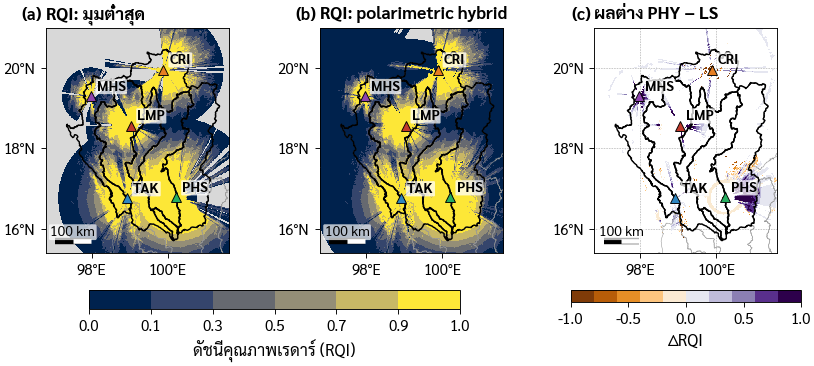

In [5]:
fig, axs = pl.subplots(1, 3, width="double", height_mm=85)
cq, nq = pl.rqi_cmap()
for ax, k_, t in [(axs[0], "rqi_LS", "RQI: มุมต่ำสุด"), (axs[1], "rqi_PHY", "RQI: polarimetric hybrid")]:
    im = mp.show_grid(ax, np.where(res[k_] > 0, res[k_], np.nan), glon, glat, cq, nq)
    mp.basemap(ax, E, title=t, scale_km=100, north=False, grid_step=2)
fig.colorbar(im, ax=axs[:2], orientation="horizontal", shrink=0.7).set_label(pl.L("rqi"))
d = res["rqi_PHY"] - res["rqi_LS"]
im2 = mp.show_grid(axs[2], np.where(np.abs(d) > 0.01, d, np.nan), glon, glat, plt.get_cmap("PuOr", 10), plt.Normalize(-1, 1))
mp.basemap(axs[2], E, title="ผลต่าง PHY − LS", scale_km=100, north=False, grid_step=2)
fig.colorbar(im2, ax=axs[2], orientation="horizontal", shrink=0.9).set_label("ΔRQI")
pl.panel_labels(axs); pl.save(fig, "04_rqi_ls_vs_phy"); plt.show()

## 6. ลำดับเวลา 15 นาที (PHY_DP)

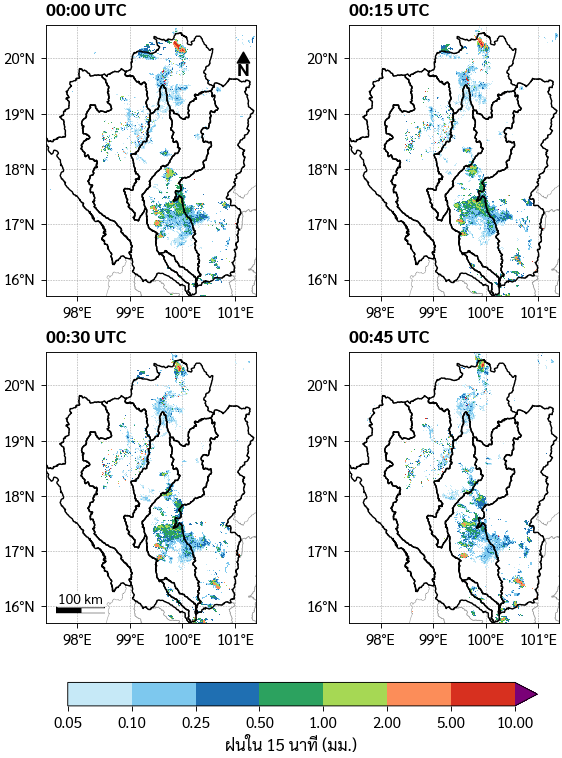

In [6]:
fig, axs = pl.subplots(2, 2, width="one_half", height_mm=175)
cm15, nm15 = pl.rain_cmap(cfg["plotting"]["rain_levels_15min"])
for i, ax in enumerate(axs.ravel()):
    im = mp.show_grid(ax, res["m15_PHY_DP"][i], glon, glat, cm15, nm15)
    mp.basemap(ax, [97.4, 101.4, 15.7, 20.6], title=str(res["times"][i])[11:16] + " UTC", scale_km=100 if i == 2 else None,
               north=(i == 0), grid_step=1, radars=False)
fig.colorbar(im, ax=axs, orientation="horizontal", shrink=0.8, extend="max").set_label("ฝนใน 15 นาที (มม.)")
pl.save(fig, "04_phy_dp_15min_sequence"); plt.show()

## 7. ฝนเฉลี่ยรายลุ่มน้ำและพื้นที่ครอบคลุม (ทั้ง 2 ชั่วโมง จากผลสำเร็จรูป)

In [7]:
from rasterio.features import rasterize
from rasterio.transform import from_origin
mb, sb, _ = mp.boundaries()
T = from_origin(glon[0] - 0.005, glat[0] + 0.005, 0.01, 0.01)
zones = {n: rasterize([(geom, 1)], out_shape=(len(glat), len(glon)), transform=T).astype(bool)
         for n, geom in zip(mb[mb.MB_CODE.isin(cfg["study_area"]["basins_of_interest"])].MBASIN_E,
                            mb[mb.MB_CODE.isin(cfg["study_area"]["basins_of_interest"])].geometry)}
_hw = sb[sb.SB_CODE.isin(cfg["study_area"]["ping_headwater_subbasins"])].geometry
hw = _hw.union_all() if hasattr(_hw, "union_all") else _hw.unary_union
zones["Ping headwater"] = rasterize([(hw, 1)], out_shape=(len(glat), len(glon)), transform=T).astype(bool)
rows = []
for tag in ["20241003_00UTC", "20241003_10UTC"]:
    d = np.load(P.products / f"mosaic_{tag}.npz")
    for zn, m in zones.items():
        for p in mosaic.PRODUCTS:
            a = d[f"h_{p}"][m]
            rows.append(dict(hour=tag[-5:], basin=zn, product=p, coverage_pct=100 * np.isfinite(a).mean(), mean_mm=np.nanmean(a)))
bt = pd.DataFrame(rows)
bt.to_csv(P.tables / "04_basin_means.csv", index=False)
bt.pivot_table(index=["hour", "basin"], columns="product", values=["coverage_pct", "mean_mm"]).round(2)

coverage_pct                      mean_mm              \
product                    HYZ_MP  LS_DP  LS_MP PHY_DP  HYZ_MP LS_DP LS_MP   
hour  basin                                                                  
00UTC Nan                   88.13  82.84  82.84  88.16    0.13  0.29  0.27   
      North Khong           73.48  70.48  70.48  73.50    0.33  0.47  0.33   
      Ping                  96.48  94.55  94.55  96.48    0.13  0.14  0.14   
      Ping headwater        90.90  88.89  88.89  90.90    0.07  0.07  0.07   
      Salawin               82.12  75.63  75.63  82.12    0.00  0.00  0.00   
      Wang                  99.55  98.97  98.97  99.55    0.11  0.11  0.11   
      Yom                   98.97  98.34  98.34  98.98    0.26  0.41  0.26   
10UTC Nan                   89.60  82.70  82.70  89.60    0.03  0.16  0.16   
      North Khong           69.75  67.13  67.13  69.75    0.15  0.15  0.15   
      Ping                  95.31  93.12  93.12  95.31    0.21  0.25  0.23   
      Ping headwater        83.91  81.66  81.66  83.91    0.12  0.12  0.12   
      Salawin               77.22  68.01  68.01  77.22    0.16  0.35  0.15   
      Wang                  99.85  98.97  98.97  99.85    0.04  0.05  0.05   
      Yom                   99.76  99.63  99.63  99.76    0.01  0.02  0.02   

                             
product              PHY_DP  
hour  basin                  
00UTC Nan              0.18  
      North Khong      0.47  
      Ping             0.13  
      Ping headwater   0.07  
      Salawin          0.00  
      Wang             0.12  
      Yom              0.46  
10UTC Nan              0.03  
      North Khong      0.15  
      Ping             0.24  
      Ping headwater   0.12  
      Salawin          0.39  
      Wang             0.04  
      Yom              0.01

## 8. ส่งออก GeoTIFF (เปิดได้ใน QGIS/ArcGIS)

In [8]:
for p in mosaic.PRODUCTS:
    mosaic.to_geotiff(P.rasters / f"04_hourly_{p}_20241003_00UTC.tif", res[f"h_{p}"], glon, glat)
mosaic.to_geotiff(P.rasters / "04_rqi_PHY_20241003_00UTC.tif", res["rqi_PHY"], glon, glat)
print(sorted(x.name for x in P.rasters.glob("04_*.tif")))

['04_hourly_HYZ_MP_20241003_00UTC.tif', '04_hourly_LS_DP_20241003_00UTC.tif', '04_hourly_LS_MP_20241003_00UTC.tif', '04_hourly_PHY_DP_20241003_00UTC.tif', '04_rqi_PHY_20241003_00UTC.tif']


---
## ✏️ แบบฝึกหัด

### แบบฝึกหัด 1 · 🟢 ป.ตรี

ภายใน 6 ลุ่มน้ำภาคเหนือ (ใช้ `zones` รวมกัน ยกเว้น Ping headwater) คิดเป็นกี่เปอร์เซ็นต์ของพื้นที่ที่ **RQI ≥ 0.5** สำหรับ LS และ PHY

In [9]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
pct_ls = None; pct_phy = None

In [10]:
#@title 🔑 เฉลยข้อ 1 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
north = np.zeros_like(zones["Ping"])
for k_, m in zones.items():
    if k_ != "Ping headwater":
        north |= m
pct_ls = 100 * np.mean(res["rqi_LS"][north] >= 0.5); pct_phy = 100 * np.mean(res["rqi_PHY"][north] >= 0.5)
print(f"RQI ≥ 0.5: LS {pct_ls:.1f}%  →  PHY {pct_phy:.1f}%")

RQI ≥ 0.5: LS 58.4%  →  PHY 62.1%


### แบบฝึกหัด 2 · 🟢 ป.ตรี

จากตาราง `bt` ช่วง **10 UTC** ลุ่มน้ำปิงและลุ่มน้ำวังมีฝนเฉลี่ยเท่าใดในแต่ละผลิตภัณฑ์ ผลิตภัณฑ์ใดให้ค่าสูงสุด เพราะอะไร

In [11]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
t10 = None

In [12]:
#@title 🔑 เฉลยข้อ 2 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
t10 = bt[(bt.hour == "10UTC") & bt.basin.isin(["Ping", "Wang"])].pivot(index="basin", columns="product", values="mean_mm").round(3)
display(t10)
print("PHY_DP มักสูงสุดเพราะใช้ R(A)/R(KDP) ในฝนหนักและแก้การบัง/VPR ทำให้มีข้อมูลในบริเวณที่ LS ไม่มี")

product,HYZ_MP,LS_DP,LS_MP,PHY_DP
basin,,,,
Ping,0.213,0.249,0.233,0.243
Wang,0.036,0.049,0.049,0.036


PHY_DP มักสูงสุดเพราะใช้ R(A)/R(KDP) ในฝนหนักและแก้การบัง/VPR ทำให้มีข้อมูลในบริเวณที่ LS ไม่มี


### แบบฝึกหัด 3 · 🟢 ป.ตรี

จาก `res['m15_PHY_DP']` สแกนใด (เวลา) มีฝนเฉลี่ยทั้งโดเมนสูงที่สุด และพื้นที่ฝน > 1 มม./15 นาที เท่าใด (km², 1 พิกเซล ≈ 1.1 × 1.05 km²)

In [13]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
best_t = None

In [14]:
#@title 🔑 เฉลยข้อ 3 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
m15 = res["m15_PHY_DP"]
means = np.nanmean(m15, axis=(1, 2)); area = np.nansum(m15 > 1, axis=(1, 2)) * 1.1 * 1.05
best_t = str(res["times"][int(np.argmax(means))])
print(pd.DataFrame({"time": res["times"], "mean_mm": means.round(4), "area_gt1mm_km2": area.round(0)}))
print("สูงสุด:", best_t)

                  time  mean_mm  area_gt1mm_km2
0  2024-10-03 00:00:00   0.0375          1851.0
1  2024-10-03 00:15:00   0.0359          1791.0
2  2024-10-03 00:30:00   0.0334          1584.0
3  2024-10-03 00:45:00   0.0293          1392.0
4  2024-10-03 01:00:00   0.0268          1374.0
สูงสุด: 2024-10-03 00:00:00


### แบบฝึกหัด 4 · 🔵 ป.โท / ส่วนขยาย

รัน `mosaic.process_hour(..., method='max')` (ใช้เวลา 1–3 นาที) แล้วเปรียบเทียบกับแบบถ่วงน้ำหนัก: บริเวณใดต่างกันมาก วิธีใดให้ขอบเขตระหว่างเรดาร์ต่อเนื่องกว่า

In [15]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
res_max = None

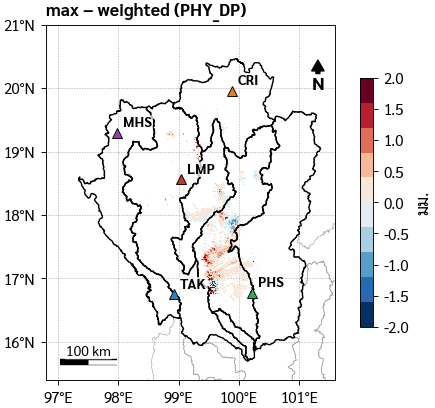

ต่างกันในพื้นที่ซ้อนทับของเรดาร์ — แบบ max มีรอยต่อ (seam) เป็นเส้นตรงที่ RQI ของสองเรดาร์เท่ากัน แบบถ่วงน้ำหนักนุ่มนวลกว่า


In [16]:
#@title 🔑 เฉลยข้อ 4 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
res_max = mosaic.process_hour(scans, terrain, cal, glon, glat, method="max", verbose=False)
d = res_max["h_PHY_DP"] - res["h_PHY_DP"]
fig, ax = pl.subplots(width="one_half", height_mm=95)
im = mp.show_grid(ax, np.where(np.abs(d) > 0.05, d, np.nan), glon, glat, plt.get_cmap("RdBu_r", 10), plt.Normalize(-2, 2))
mp.basemap(ax, E, title="max − weighted (PHY_DP)", scale_km=100)
fig.colorbar(im, ax=ax, shrink=0.7).set_label("มม."); plt.show()
print("ต่างกันในพื้นที่ซ้อนทับของเรดาร์ — แบบ max มีรอยต่อ (seam) เป็นเส้นตรงที่ RQI ของสองเรดาร์เท่ากัน แบบถ่วงน้ำหนักนุ่มนวลกว่า")

### แบบฝึกหัด 5 · 🔵 ป.โท / ส่วนขยาย

ลดเกณฑ์ฐานลำคลื่นจาก 150 ม. เป็น **50 ม.** (`clearance=50`) พื้นที่ที่ใช้มุมต่ำสุดเพิ่มขึ้นหรือไม่ และมีความเสี่ยงอะไร (คำใบ้: clutter ใกล้ PHS)

In [17]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
res50 = None

In [18]:
#@title 🔑 เฉลยข้อ 5 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
res50 = mosaic.process_hour(scans, terrain, cal, glon, glat, clearance=50.0, verbose=False)
for k_ in ["rqi_HYZ", "rqi_PHY"]:
    print(k_, "RQI ≥ 0.5:", f"{100*np.mean(res[k_] >= 0.5):.1f}% → {100*np.mean(res50[k_] >= 0.5):.1f}%")
dd = res50["h_PHY_DP"] - res["h_PHY_DP"]
print("พิกเซลที่ฝนเพิ่ม > 1 มม.:", int(np.nansum(dd > 1)), "→ ตรวจตำแหน่ง: มักอยู่ใกล้ PHS ที่มุม 0.48° มี clutter/AP")

rqi_HYZ RQI ≥ 0.5: 30.2% → 30.4%
rqi_PHY RQI ≥ 0.5: 30.2% → 30.4%
พิกเซลที่ฝนเพิ่ม > 1 มม.: 185 → ตรวจตำแหน่ง: มักอยู่ใกล้ PHS ที่มุม 0.48° มี clutter/AP


---
## 💡 คำถามชวนคิดและต่อยอด
- JMA (ญี่ปุ่น) ใช้ค่า **สูงสุด** ของเรดาร์ที่ซ้อนทับ (Makihara 2000) ส่วน MRMS ใช้ถ่วงน้ำหนัก ข้อดีข้อเสียของแต่ละแบบในพื้นที่ภูเขาคืออะไร
- ถ้าเรดาร์บางตัวไม่มีข้อมูลบางสแกน (เช่น เรดาร์น่านปิดซ่อม) โมเสคควรจัดการอย่างไรเพื่อไม่ให้เกิด "รู" หรือรอยต่อ
- RQI ควรถูกส่งไปพร้อมฝนให้ผู้ใช้ปลายทาง (เช่น หน่วยงานเตือนภัย) หรือไม่ จะนำเสนออย่างไรให้เข้าใจง่าย
- 🔵 ลองโมเสค **Z** ก่อนแล้วค่อยแปลงเป็น R เทียบกับโมเสค R โดยตรง ต่างกันอย่างไร

## 📚 อ้างอิง
- Fulton, R.A. et al. (1998). The WSR-88D rainfall algorithm. *Wea. Forecasting* 13:377–395.
- Zhang, J. et al. (2016). Multi-Radar Multi-Sensor (MRMS) quantitative precipitation estimation. *Bull. Amer. Meteor. Soc.* 97:621–638.
- Makihara, Y. (2000). Algorithms for precipitation nowcasting focused on detailed analysis using radar and raingauge data. *Tech. Rep. MRI* 39:63–111.
- Germann, U. et al. (2022). Weather radar in complex orography. *Remote Sensing* 14:503.

In [19]:
#@title 💾 บันทึกผลลัพธ์ขึ้น GitHub (fork ของคุณเอง) { display-mode: "form" }
#@markdown ใส่รหัสนิสิต แล้วรันเซลล์นี้ (ต้องตั้ง Colab Secrets `GITHUB_USER` และ `GITHUB_TOKEN` ก่อน — ดูขั้นตอนใน notebook 00)
STUDENT_ID = ""  #@param {type:"string"}
if STUDENT_ID:
    colab.save_to_fork(STUDENT_ID, message="NB04: results")
else:
    print("ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)")

ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)
